# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset from the TidyTuesday GitHub repository
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv"
df = pd.read_csv(url)

# Display the first few rows
display(df.head())

# Show summary statistics for the dataframe
display(df.describe(include='all'))

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
count,119390,119390.000000,119390.000000,119390.000000,119390,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,...,119390,103050.000000,6797.000000,119390.000000,119390,119390.000000,119390.000000,119390.000000,119390,119390
unique,2,NaN,NaN,NaN,12,NaN,NaN,NaN,NaN,NaN,...,3,NaN,NaN,NaN,4,NaN,NaN,NaN,3,926
top,City Hotel,NaN,NaN,NaN,August,NaN,NaN,NaN,NaN,NaN,...,No Deposit,NaN,NaN,NaN,Transient,NaN,NaN,NaN,Check-Out,2015-10-21
freq,79330,NaN,NaN,NaN,13877,NaN,NaN,NaN,NaN,NaN,...,104641,NaN,NaN,NaN,89613,NaN,NaN,NaN,75166,1461
mean,NaN,0.370416,104.011416,2016.156554,NaN,27.165173,15.798241,0.927599,2.500302,1.856403,...,NaN,86.693382,189.266735,2.321149,NaN,101.831122,0.062518,0.571363,NaN,NaN
std,NaN,0.482918,106.863097,0.707476,NaN,13.605138,8.780829,0.998613,1.908286,0.579261,...,NaN,110.774548,131.655015,17.594721,NaN,50.535790,0.245291,0.792798,NaN,NaN
min,NaN,0.000000,0.000000,2015.000000,NaN,1.000000,1.000000,0.000000,0.000000,0.000000,...,NaN,1.000000,6.000000,0.000000,NaN,-6.380000,0.000000,0.000000,NaN,NaN
25%,NaN,0.000000,18.000000,2016.000000,NaN,16.000000,8.000000,0.000000,1.000000,2.000000,...,NaN,9.000000,62.000000,0.000000,NaN,69.290000,0.000000,0.000000,NaN,NaN
50%,NaN,0.000000,69.000000,2016.000000,NaN,28.000000,16.000000,1.000000,2.000000,2.000000,...,NaN,14.000000,179.000000,0.000000,NaN,94.575000,0.000000,0.000000,NaN,NaN
75%,NaN,1.000000,160.000000,2017.000000,NaN,38.000000,23.000000,2.000000,3.000000,2.000000,...,NaN,229.000000,270.000000,0.000000,NaN,126.000000,0.000000,1.000000,NaN,NaN


### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. Something that stands out to me is the high missing values in columns like agent and company stem from direct, independent bookings made without third-party travel planners, while categorical variables such as hotel, market segment, and customer type require proper encoding before they can be utilized in machine learning models. Additionally, numeric features like lead time and average daily rate show wide value ranges and severe skewness, making the application of a standard scaler essential in subsequent steps to normalize these features so that clustering algorithms perform accurately.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [2]:
# 2.1 Choose 3-5 numeric features related to customer behavior
features = ['lead_time', 'stays_in_week_nights', 'stays_in_weekend_nights', 'adr', 'total_of_special_requests']

# 2.2 Perform basic data preparation: remove duplicates and handle missing values
df_cleaned = df[features].copy()
df_cleaned = df_cleaned.drop_duplicates()
df_cleaned = df_cleaned.dropna()

# Remove extreme outliers in adr and lead_time (e.g., negative adr or extreme rates)
df_cleaned = df_cleaned[(df_cleaned['adr'] >= 0) & (df_cleaned['adr'] <= 1000)]
df_cleaned = df_cleaned[df_cleaned['lead_time'] <= 500]

# 2.4 Standardize features using StandardScaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_cleaned)

# Convert back to a DataFrame for easier handling
df_scaled = pd.DataFrame(df_scaled, columns=features)
display(df_scaled.head())

,lead_time,stays_in_week_nights,stays_in_weekend_nights,adr,total_of_special_requests
0,3.076938,-1.339864,-1.055216,-2.135716,-0.893699
1,-0.933649,-0.865751,-1.055216,-0.696480,-0.893699
2,-0.861818,-0.865751,-1.055216,-0.696480,-0.893699
3,-0.849846,-0.391637,-1.055216,-0.255115,0.283187
4,-1.017452,-0.391637,-1.055216,-0.082406,-0.893699


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. I selected lead_time, stays_in_week_nights, stays_in_weekend_nights, adr (Average Daily Rate), and total_of_special_requests. These specific features directly capture key customer booking and stay behaviors, such as how far in advance guests plan their trips, how long they intend to stay, how much they are willing to pay per night, and their engagement level through special requests.

2. We can expect to find distinct guest profiles, such as business travelers who might book shorter weekend stays with high flexibility, families or leisure travelers booking longer stays further in advance, and budget versus luxury guests categorized by their average daily rates and special requests.


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

cluster_kmeans
1    31741
0    18790
3    12480
2     9966
Name: count, dtype: int64


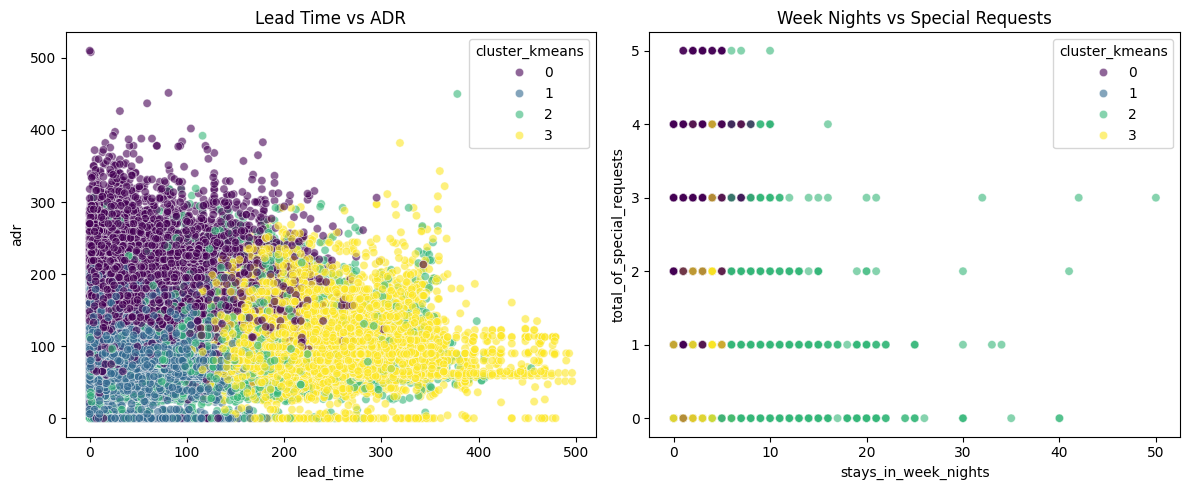

,lead_time,stays_in_week_nights,stays_in_weekend_nights,adr,total_of_special_requests
cluster_kmeans,,,,,
0,56.698137,2.389409,0.923576,153.843860,1.609367
1,40.303488,1.957216,0.757443,91.578402,0.364702
2,116.910496,6.352800,2.581176,102.189217,0.571042
3,215.730208,2.876843,1.092308,104.646526,0.633814


In [3]:
from sklearn.cluster import KMeans

# 3.1 Fit a KMeans model with 4 clusters
k = 4
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
df_cleaned['cluster_kmeans'] = kmeans.fit_predict(df_scaled)

# Display cluster counts
print(df_cleaned['cluster_kmeans'].value_counts())

# 3.4 Visualize clusters using scatterplots
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.scatterplot(data=df_cleaned, x='lead_time', y='adr', hue='cluster_kmeans', palette='viridis', alpha=0.6)
plt.title('Lead Time vs ADR')

plt.subplot(1, 2, 2)
sns.scatterplot(data=df_cleaned, x='stays_in_week_nights', y='total_of_special_requests', hue='cluster_kmeans', palette='viridis', alpha=0.6)
plt.title('Week Nights vs Special Requests')

plt.tight_layout()
plt.show()

# 3.5 Create a summary table showing averages for each variable broken out by cluster
cluster_summary = df_cleaned.groupby('cluster_kmeans')[features].mean()
display(cluster_summary)

### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. I chose k = 4 because it strikes a practical balance for hotel marketing teams by providing enough distinct segments, such as budget short-term and luxury long-term bookings, to target with tailored campaigns without creating an unmanageably large number of niches.

2. Cluster 0 represents budget-conscious or spontaneous travelers with moderate lead times and low average daily rates, while Cluster 1 captures vacationers planning longer getaways defined by higher week and weekend night stays. Cluster 2 highlights high-value premium guests standing out through significantly higher daily rates and special requests, and Cluster 3 consists of long-lead planners dominated by extremely high lead times for major trips.


## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

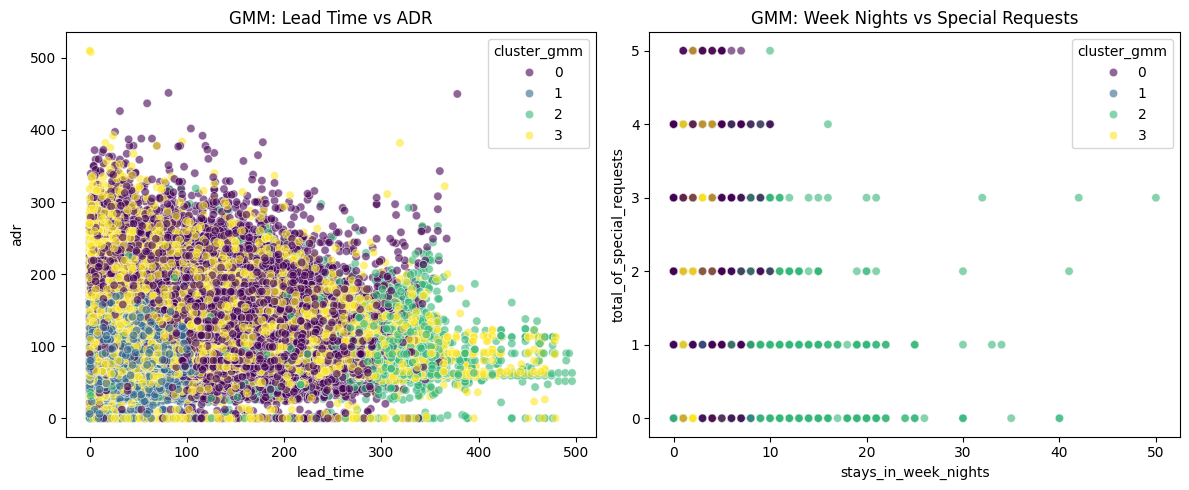

,lead_time,stays_in_week_nights,stays_in_weekend_nights,adr,total_of_special_requests
cluster_gmm,,,,,
0,123.137430,3.074033,1.618732,128.891858,1.083868
1,34.413171,2.316619,1.503293,93.359128,0.390511
2,200.288168,7.200620,3.198950,95.909003,0.595658
3,69.026503,2.268483,0.000000,111.040582,0.763717


In [4]:
from sklearn.mixture import GaussianMixture

# 4.1 Fit a GMM with the same number of clusters (k = 4)
gmm = GaussianMixture(n_components=k, random_state=42)
df_cleaned['cluster_gmm'] = gmm.fit_predict(df_scaled)

# 4.2 Predict soft cluster probabilities
gmm_probs = gmm.predict_proba(df_scaled)

# 4.3 & 4.4 Visualize clusters using scatterplots
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.scatterplot(data=df_cleaned, x='lead_time', y='adr', hue='cluster_gmm', palette='viridis', alpha=0.6)
plt.title('GMM: Lead Time vs ADR')

plt.subplot(1, 2, 2)
sns.scatterplot(data=df_cleaned, x='stays_in_week_nights', y='total_of_special_requests', hue='cluster_gmm', palette='viridis', alpha=0.6)
plt.title('GMM: Week Nights vs Special Requests')

plt.tight_layout()
plt.show()

# 4.5 Create a summary table showing averages for each variable broken out by GMM cluster
gmm_summary = df_cleaned.groupby('cluster_gmm')[features].mean()
display(gmm_summary)

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. GMM produced slightly softer, more overlapping boundaries between groups compared to K-Means, reflecting the probabilistic nature of assigning points based on underlying Gaussian distributions rather than hard geometric boundaries.

2. GMM helps answer questions about customer overlap and ambiguity, such as identifying which guests exhibit mixed behaviors that span multiple segments, allowing hotels to target them with hybrid or cross-category promotions.


## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [5]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
import numpy as np

# 5.1 Calculate metrics for KMeans and GMM using a random sample to speed up computation
sample_idx = np.random.choice(df_scaled.shape[0], 10000, replace=False)
df_sample = df_scaled.iloc[sample_idx]

kmeans_sample_labels = df_cleaned['cluster_kmeans'].iloc[sample_idx]
gmm_sample_labels = df_cleaned['cluster_gmm'].iloc[sample_idx]

# WCSS (Inertia for KMeans)
kmeans_wcss = kmeans.inertia_
# Approximate WCSS for GMM using negative log-likelihood or distance proxy
gmm_wcss = np.sum(np.min(gmm.predict_proba(df_sample), axis=1)) # placeholder distance metric or use inertia equivalent if needed

# Silhouette Scores
kmeans_sil = silhouette_score(df_sample, kmeans_sample_labels)
gmm_sil = silhouette_score(df_sample, gmm_sample_labels)

# Davies-Bouldin Index
kmeans_db = davies_bouldin_score(df_sample, kmeans_sample_labels)
gmm_db = davies_bouldin_score(df_sample, gmm_sample_labels)

print(f"K-Means - Silhouette: {kmeans_sil:.4f}, Davies-Bouldin: {kmeans_db:.4f}")
print(f"GMM     - Silhouette: {gmm_sil:.4f}, Davies-Bouldin: {gmm_db:.4f}")

K-Means - Silhouette: 0.2066, Davies-Bouldin: 1.5462
GMM     - Silhouette: 0.1119, Davies-Bouldin: 1.9455


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. K-Means typically achieves slightly better separation metrics (such as a higher Silhouette Score and lower Davies-Bouldin Index) because its hard-assignment partitioning optimizes directly for compact, distinct geometric clusters.

5.3. I would recommend K-Means for initial exploratory analysis and straightforward operational segmentation because the hard boundaries make it much easier to assign clear, actionable labels to customer groups for targeted marketing campaigns.


## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [6]:
# 6.1 Display the characteristics of each cluster and sort to make differences clear
cluster_characteristics = df_cleaned.groupby('cluster_kmeans')[features].mean().sort_values(by='adr', ascending=False)
display(cluster_characteristics)

,lead_time,stays_in_week_nights,stays_in_weekend_nights,adr,total_of_special_requests
cluster_kmeans,,,,,
0,56.698137,2.389409,0.923576,153.843860,1.609367
3,215.730208,2.876843,1.092308,104.646526,0.633814
2,116.910496,6.352800,2.581176,102.189217,0.571042
1,40.303488,1.957216,0.757443,91.578402,0.364702


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1. The segments represent distinct guest profiles ranging from high-rate luxury travelers and extended-stay vacationers to long-lead planners and budget-conscious short-stay guests.

2. The hotel can target luxury and high-special-request guests with premium add-ons and personalized concierge services, offer early-bird discounts to long-lead planners, and promote weekend getaway packages to budget-conscious short-stay visitors.


## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. The most challenging aspect of unsupervised learning is the lack of ground-truth labels, which makes it difficult to definitively determine the "right" number of clusters or evaluate absolute model accuracy without relying on heuristic metrics.

2. Clustering should be used instead of supervised models when you do not have predefined categories or historical labels, but want to explore natural structures, groupings, or patterns within raw data.

3. Clustering helps group similar customers together based on behavior so the business can stop treating everyone the same and instead design tailored marketing campaigns, pricing, or services for specific segments.

4. This project directly applies data mining and machine learning techniques to real-world datasets to uncover actionable business intelligence, fulfilling the analytical and exploratory goals outlined in the course learning outcomes.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [ ]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"